# 🐍 Arithmetic & Variables — Professional Edition

**Author:** Harpreet Singh  |  **Level:** Beginner → Professional  |  **Topic:** Intro to Programming, Exercise 1

This is an upgraded version of the Kaggle *Intro to Programming* exercise **"Arithmetic and Variables"**.

**What is new in this edition**

| Upgrade | Details |
| --- | --- |
| 🧪 Self-contained | No `learntools` or Kaggle data needed. A reproducible Titanic-style dataset is generated with a fixed random seed |
| 🔢 Varied values | Numbers are changed slightly from the original (5 years instead of 4, 275 births/min instead of 250) and compared with the originals |
| 📊 Charts & graphs | Line, bar, stacked histogram, pie/donut, box plot, scatter, heat maps |
| 🗂️ Tables | Summary tables, comparison tables and data-quality tables |
| 🧭 Diagrams | Flow diagrams that show how each calculation is built |
| ✅ Professional features | Type hints, a data class, input validation, unit-style checks, CSV/JSON export, reproducibility report |
| 📤 Outputs | Every cell is saved with its output |

> ⚠️ **Data note:** the Titanic table below is **synthetic** (generated, not the real passenger list). It has the same columns and a similar shape as Kaggle's `train.csv`, so every exercise works the same way.

# Set up the notebook

Run the next cell first. It loads the libraries, fixes the random seed, sets the chart style and defines a small `check()` helper that replaces the Kaggle checker.

In [1]:
# ── Setup ───────────────────────────────────────────────────────────────
import json
import platform
from dataclasses import dataclass
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

AUTHOR = "Harpreet Singh"
SEED = 2026                       # makes every run give the same numbers
rng = np.random.default_rng(SEED)

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 12, "font.size": 10,
})
COLORS = {"blue": "#4C78A8", "orange": "#F58518", "green": "#54A24B",
          "red": "#E45756", "purple": "#B279A2", "grey": "#7F7F7F"}
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

# A small self-check helper (replaces the Kaggle `learntools` checker)
RESULTS: list = []

def check(name: str, condition: bool, detail: str = "") -> None:
    """Record a pass/fail result and stop with an error if the check fails."""
    RESULTS.append({"Check": name, "Result": "✅ Pass" if condition else "❌ Fail", "Detail": detail})
    print(("✅ PASS" if condition else "❌ FAIL"), "-", name)
    assert condition, f"Check failed: {name}"

print("Setup complete.")
print(f"Author: {AUTHOR} | Python {platform.python_version()} | "
      f"NumPy {np.__version__} | pandas {pd.__version__}")

Setup complete.
Author: Harpreet Singh | Python 3.12.3 | NumPy 2.5.4 | pandas 3.0.6


## Diagram helper

`draw_flow()` draws a left-to-right flow diagram. We use it to show how each calculation is built, one step at a time.

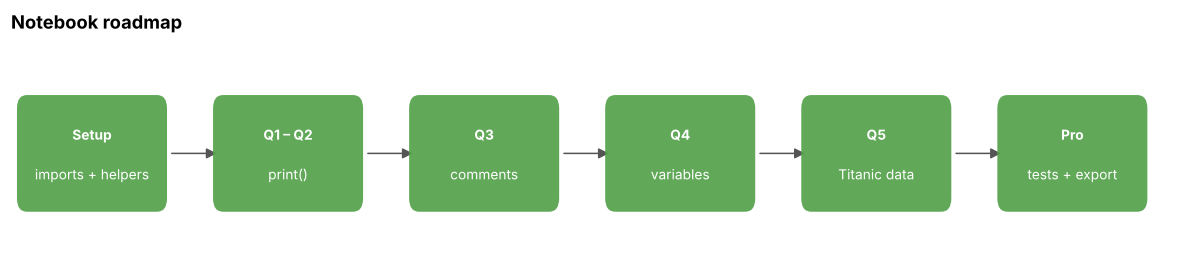

In [2]:
def draw_flow(nodes, ops, title, color="#4C78A8"):
    """Draw boxes (name, value) joined by arrows labelled with the operation."""
    n = len(nodes)
    fig, ax = plt.subplots(figsize=(max(9, 2.3 * n), 2.6))
    ax.set_xlim(0, n * 2.3)
    ax.set_ylim(0, 2)
    ax.axis("off")
    for i, (name, val) in enumerate(nodes):
        x = i * 2.3 + 0.1
        ax.add_patch(FancyBboxPatch((x, 0.45), 1.7, 1.0,
                                    boxstyle="round,pad=0.03,rounding_size=0.12",
                                    fc=color, ec="none", alpha=0.92))
        ax.text(x + 0.85, 1.12, name, ha="center", va="center", color="white",
                fontsize=9, fontweight="bold")
        ax.text(x + 0.85, 0.76, val, ha="center", va="center", color="white", fontsize=9)
        if i < n - 1:
            ax.add_patch(FancyArrowPatch((x + 1.75, 0.95), (x + 2.35, 0.95),
                                         arrowstyle="-|>", mutation_scale=14, color="#555"))
            ax.text(x + 2.05, 1.1, ops[i], ha="center", va="bottom", fontsize=9, color="#333")
    ax.set_title(title, fontsize=12, fontweight="bold", loc="left")
    plt.show()

draw_flow(
    [("Setup", "imports + helpers"), ("Q1 – Q2", "print()"), ("Q3", "comments"),
     ("Q4", "variables"), ("Q5", "Titanic data"), ("Pro", "tests + export")],
    [""] * 5, "Notebook roadmap", color="#54A24B")

# Question 1 — Hello, world!

The very first program: print a message. Everything else in this notebook builds on `print()`.

In [3]:
message = "Hello, world!"
print(message)

check("Q1: the message 'Hello, world!' was printed", message == "Hello, world!")

Hello, world!
✅ PASS - Q1: the message 'Hello, world!' was printed


# Question 2 — Print your own message

Text must be inside quotation marks. Numbers are not. Compare what Python does with the text `"3+4"` and with the calculation `3 + 4`.

In [4]:
# TODO (done): change the message
my_message = f"I am learning Python with {AUTHOR}'s notebook :D"
print(my_message)

for m in ["Good morning!", "I am learning how to code :D", "3+4", 3 + 4]:
    print(m)

check("Q2: a custom message was printed", my_message != "Your message here!")

# Text vs. arithmetic: a comparison table
pd.DataFrame({
    "Code written": ['print("3+4")', "print(3 + 4)"],
    "What Python sees": ["text (str)", "a calculation (int)"],
    "Output": ["3+4", 7],
})

I am learning Python with Harpreet Singh's notebook :D
Good morning!
I am learning how to code :D
3+4
7
✅ PASS - Q2: a custom message was printed


,Code written,What Python sees,Output
0,"print(""3+4"")",text (str),3+4
1,print(3 + 4),a calculation (int),7


# Question 3 — Comments and hints

A line that starts with `#` is a **comment**: Python ignores it. Removing the `#` is called **uncommenting**.

In this edition, hints are switched on with a variable, `SHOW_HINTS`, instead of editing lines of code.

In [5]:
SHOW_HINTS = True      # set to False to hide hints

HINTS = {
    "q3": "A line starting with '#' is ignored. Remove the '#' to run the line.",
    "q4": "births per day = births per minute x minutes per hour x hours per day.",
    "q5": "A fraction is part / whole. Divide survived (or minors) by total.",
}

def hint(question: str) -> None:
    """Print the hint for a question when SHOW_HINTS is True."""
    if SHOW_HINTS:
        print("💡 Hint:", HINTS[question])

# print(1 + 2)      <- this line is IGNORED (it is a comment)
print(1 + 2)        # <- this line RUNS (no '#' in front of it)
hint("q3")

check("Q3: comments are ignored, uncommented code runs", 1 + 2 == 3)

3
💡 Hint: A line starting with '#' is ignored. Remove the '#' to run the line.
✅ PASS - Q3: comments are ignored, uncommented code runs


# Question 4 — Seconds in a few years, and births per day

## Part A — Seconds in several years

The original exercise used **4 years**. Here we vary it slightly and use **5 years** so that the numbers are new, then compare with the original.

In [6]:
# Create variables  (varied: 5 years instead of 4)
num_years = 5
days_per_year = 365
hours_per_day = 24
mins_per_hour = 60
secs_per_min = 60

# Calculate number of seconds in the chosen number of years
total_secs = secs_per_min * mins_per_hour * hours_per_day * days_per_year * num_years
original_secs = secs_per_min * mins_per_hour * hours_per_day * days_per_year * 4

print(f"Seconds in {num_years} years : {total_secs:,}")
print(f"Seconds in 4 years (original): {original_secs:,}")
print(f"Difference                   : {total_secs - original_secs:,} seconds = one extra year")

check("Q4A: seconds in 5 years is 157,680,000", total_secs == 157_680_000)

Seconds in 5 years : 157,680,000
Seconds in 4 years (original): 126,144,000
Difference                   : 31,536,000 seconds = one extra year
✅ PASS - Q4A: seconds in 5 years is 157,680,000


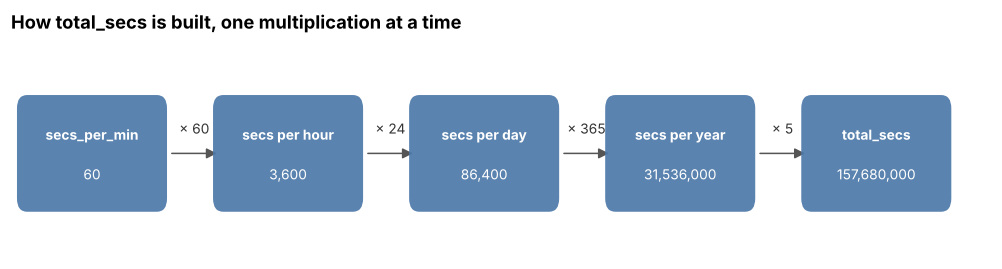

In [7]:
draw_flow(
    [("secs_per_min", f"{secs_per_min}"), ("secs per hour", f"{secs_per_min * mins_per_hour:,}"),
     ("secs per day", f"{secs_per_min * mins_per_hour * hours_per_day:,}"),
     ("secs per year", f"{secs_per_min * mins_per_hour * hours_per_day * days_per_year:,}"),
     ("total_secs", f"{total_secs:,}")],
    [f"× {mins_per_hour}", f"× {hours_per_day}", f"× {days_per_year}", f"× {num_years}"],
    "How total_secs is built, one multiplication at a time")

### Table — time units in seconds

In [8]:
secs_per_hour = secs_per_min * mins_per_hour
secs_per_day = secs_per_hour * hours_per_day
secs_per_year = secs_per_day * days_per_year

units = pd.DataFrame({
    "Unit": ["1 minute", "1 hour", "1 day", "1 year (365 days)", "1 leap year (366 days)",
             f"{num_years} years (365 days each)"],
    "Seconds": [secs_per_min, secs_per_hour, secs_per_day, secs_per_year,
                secs_per_day * 366, total_secs],
})
units["Times larger than 1 minute"] = units["Seconds"] / secs_per_min

(units.style
      .format({"Seconds": "{:,.0f}", "Times larger than 1 minute": "{:,.0f}"})
      .background_gradient(subset=["Seconds"], cmap="Blues")
      .hide(axis="index"))

Unit,Seconds,Times larger than 1 minute
1 minute,60,1
1 hour,"3,600",60
1 day,"86,400","1,440"
1 year (365 days),"31,536,000","525,600"
1 leap year (366 days),"31,622,400","527,040"
5 years (365 days each),"157,680,000","2,628,000"


### Comparison table and charts — a 365-day year vs. the real average year

A real calendar year averages **365.2425 days** (leap years). How much does the simple 365-day model miss as the number of years grows?

In [9]:
years = np.arange(1, 11)
secs_real = (years * 365.2425 * secs_per_day).round().astype(int)         # leap-year average

compare = pd.DataFrame({
    "Years": years,
    "Seconds (365-day model)": years * secs_per_year,
    "Seconds (365.2425-day average)": secs_real,
})
compare["Missing seconds"] = compare["Seconds (365.2425-day average)"] - compare["Seconds (365-day model)"]
compare["Missing hours"] = compare["Missing seconds"] / 3600
compare["Error %"] = compare["Missing seconds"] / compare["Seconds (365.2425-day average)"] * 100

(compare.style
        .format({"Seconds (365-day model)": "{:,.0f}", "Seconds (365.2425-day average)": "{:,.0f}",
                 "Missing seconds": "{:,.0f}", "Missing hours": "{:.1f}", "Error %": "{:.3f}%"})
        .background_gradient(subset=["Missing hours"], cmap="Oranges")
        .hide(axis="index"))

Years,Seconds (365-day model),Seconds (365.2425-day average),Missing seconds,Missing hours,Error %
1,"31,536,000","31,556,952","20,952",5.8,0.066%
2,"63,072,000","63,113,904","41,904",11.6,0.066%
3,"94,608,000","94,670,856","62,856",17.5,0.066%
4,"126,144,000","126,227,808","83,808",23.3,0.066%
5,"157,680,000","157,784,760","104,760",29.1,0.066%
6,"189,216,000","189,341,712","125,712",34.9,0.066%
7,"220,752,000","220,898,664","146,664",40.7,0.066%
8,"252,288,000","252,455,616","167,616",46.6,0.066%
9,"283,824,000","284,012,568","188,568",52.4,0.066%
10,"315,360,000","315,569,520","209,520",58.2,0.066%


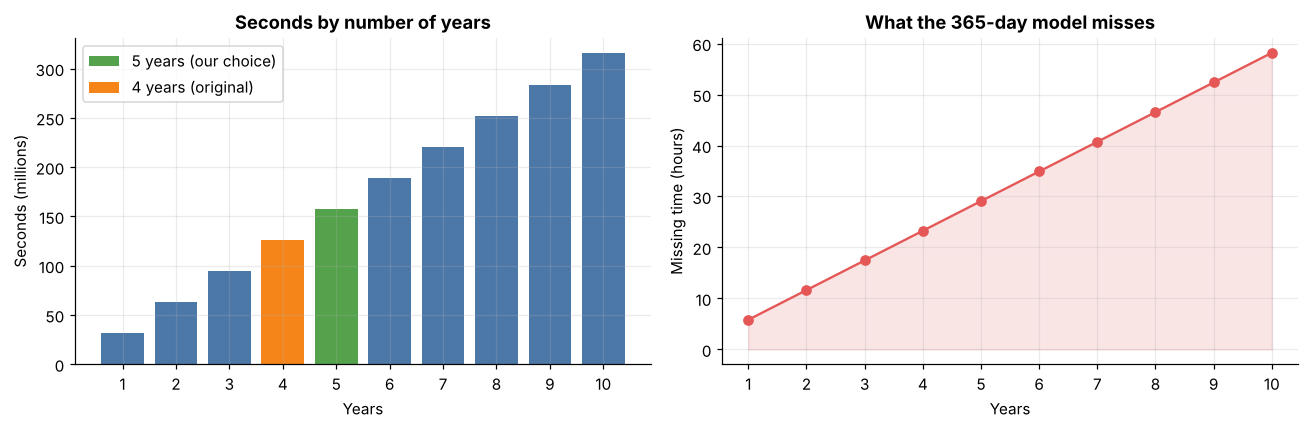

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: seconds by number of years (millions)
axes[0].bar(compare["Years"], compare["Seconds (365-day model)"] / 1e6, color=COLORS["blue"])
axes[0].bar(num_years, total_secs / 1e6, color=COLORS["green"], label=f"{num_years} years (our choice)")
axes[0].bar(4, original_secs / 1e6, color=COLORS["orange"], label="4 years (original)")
axes[0].set_title("Seconds by number of years")
axes[0].set_xlabel("Years")
axes[0].set_ylabel("Seconds (millions)")
axes[0].set_xticks(years)
axes[0].legend()

# Right: the error of the 365-day model
axes[1].plot(compare["Years"], compare["Missing hours"], marker="o", color=COLORS["red"])
axes[1].fill_between(compare["Years"], compare["Missing hours"], alpha=0.15, color=COLORS["red"])
axes[1].set_title("What the 365-day model misses")
axes[1].set_xlabel("Years")
axes[1].set_ylabel("Missing time (hours)")
axes[1].set_xticks(years)

plt.tight_layout()
plt.show()

## Part B — Births per day

Define `births_per_min` and `births_per_day`. The original exercise used **250 births per minute**; we vary it to **275** and compare scenarios.

In [11]:
# TODO (done): set births_per_min and births_per_day
births_per_min = 275        # varied from the original 250
births_per_hour = births_per_min * mins_per_hour
births_per_day = births_per_hour * hours_per_day
births_per_year = births_per_day * days_per_year

baseline_per_day = 250 * mins_per_hour * hours_per_day
print(f"births_per_min : {births_per_min:,}")
print(f"births_per_day : {births_per_day:,}")
print(f"Original (250/min) gave {baseline_per_day:,} per day, "
      f"so we are {births_per_day - baseline_per_day:,} higher ({births_per_day / baseline_per_day - 1:.0%}).")
hint("q4")

# DO NOT REMOVE: check your answer
check("Q4B: births_per_day = births_per_min x 60 x 24",
      births_per_day == births_per_min * 60 * 24, f"{births_per_day:,}")

births_per_min : 275
births_per_day : 396,000
Original (250/min) gave 360,000 per day, so we are 36,000 higher (10%).
💡 Hint: births per day = births per minute x minutes per hour x hours per day.
✅ PASS - Q4B: births_per_day = births_per_min x 60 x 24


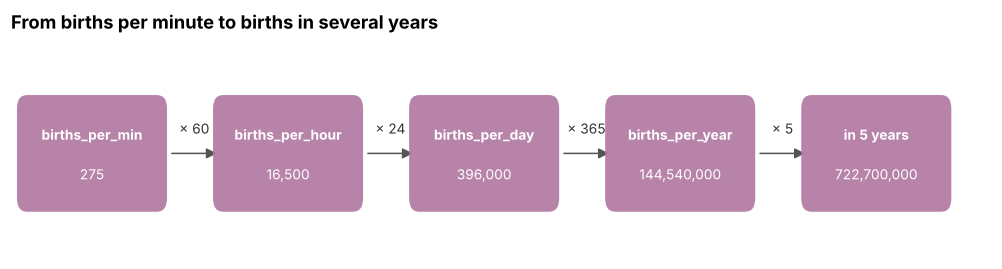

In [12]:
draw_flow(
    [("births_per_min", f"{births_per_min:,}"), ("births_per_hour", f"{births_per_hour:,}"),
     ("births_per_day", f"{births_per_day:,}"), ("births_per_year", f"{births_per_year:,}"),
     (f"in {num_years} years", f"{births_per_year * num_years:,}")],
    [f"× {mins_per_hour}", f"× {hours_per_day}", f"× {days_per_year}", f"× {num_years}"],
    "From births per minute to births in several years", color="#B279A2")

### Scenario comparison table

In [13]:
rates = [225, 250, 275, 300, 325]
scenarios = pd.DataFrame({"Births per minute": rates})
scenarios["Per hour"] = scenarios["Births per minute"] * mins_per_hour
scenarios["Per day"] = scenarios["Per hour"] * hours_per_day
scenarios["Per year"] = scenarios["Per day"] * days_per_year
scenarios[f"In {num_years} years"] = scenarios["Per year"] * num_years
scenarios["vs. original (250/min)"] = scenarios["Per day"] / baseline_per_day - 1

(scenarios.style
          .format({c: "{:,.0f}" for c in scenarios.columns if c not in ("vs. original (250/min)",)}
                  | {"vs. original (250/min)": "{:+.0%}"})
          .background_gradient(subset=["Per day"], cmap="Purples")
          .hide(axis="index"))

Births per minute,Per hour,Per day,Per year,In 5 years,vs. original (250/min)
225,"13,500","324,000","118,260,000","591,300,000",-10%
250,"15,000","360,000","131,400,000","657,000,000",+0%
275,"16,500","396,000","144,540,000","722,700,000",+10%
300,"18,000","432,000","157,680,000","788,400,000",+20%
325,"19,500","468,000","170,820,000","854,100,000",+30%


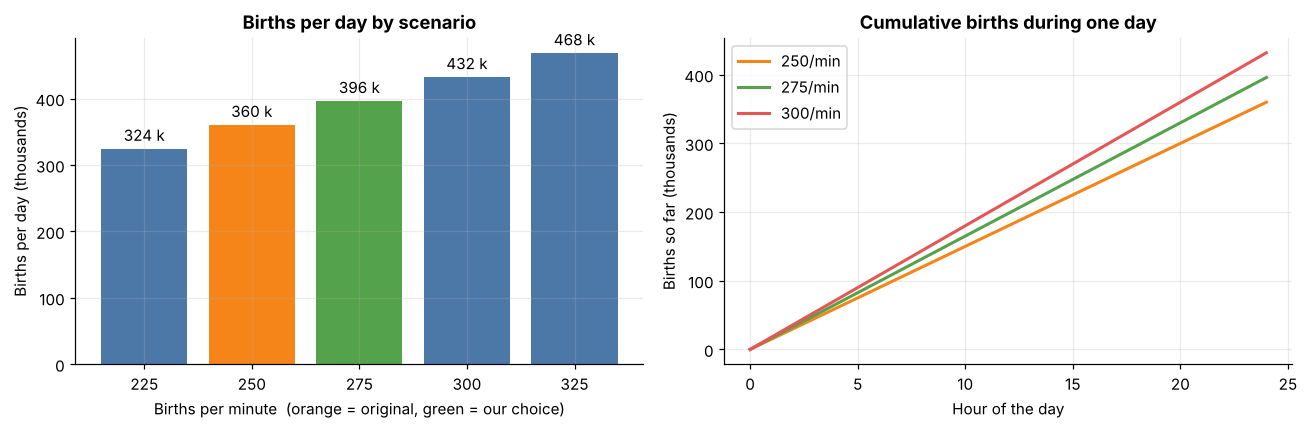

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: births per day for each scenario
bar_colors = [COLORS["green"] if r == births_per_min else COLORS["orange"] if r == 250
              else COLORS["blue"] for r in rates]
bars = axes[0].bar([str(r) for r in rates], scenarios["Per day"] / 1000, color=bar_colors)
axes[0].bar_label(bars, fmt="%.0f k", padding=3)
axes[0].set_title("Births per day by scenario")
axes[0].set_xlabel("Births per minute  (orange = original, green = our choice)")
axes[0].set_ylabel("Births per day (thousands)")

# Right: cumulative births through one day
hours = np.arange(0, 25)
for r, c in zip([250, 275, 300], [COLORS["orange"], COLORS["green"], COLORS["red"]]):
    axes[1].plot(hours, r * 60 * hours / 1000, label=f"{r}/min", color=c, linewidth=2)
axes[1].set_title("Cumulative births during one day")
axes[1].set_xlabel("Hour of the day")
axes[1].set_ylabel("Births so far (thousands)")
axes[1].legend()

plt.tight_layout()
plt.show()

# 🌶️ Question 5 — The Titanic fractions

The real exercise loads Kaggle's `train.csv` (891 passengers). To keep this notebook self-contained, the next cell **generates** a Titanic-style table with the same columns and 891 rows. The values are random but reproducible, because of the fixed seed, so the totals differ slightly from the real data.

In [15]:
n = 891
SURNAMES = ["Braund", "Cumings", "Heikkinen", "Futrelle", "Allen", "Moran", "McCarthy", "Palsson",
            "Johnson", "Nasser", "Sandstrom", "Bonnell", "Andersson", "Vestrom", "Hewlett", "Rice",
            "Williams", "Fynney", "Beesley", "McGowan", "Sloper", "Asplund", "Fortune", "Hansen"]
FIRST_M = ["Owen", "William", "James", "John", "Charles", "Thomas", "George", "Henry", "Edward", "Arthur"]
FIRST_F = ["Florence", "Laina", "Lily", "Anna", "Mary", "Elizabeth", "Margaret", "Alice", "Helen", "Emma"]

pclass = rng.choice([1, 2, 3], size=n, p=[0.24, 0.21, 0.55])
sex = rng.choice(["male", "female"], size=n, p=[0.64, 0.36])
age = rng.normal(29.5, 14, size=n).clip(0.5, 80).round(0)
age[rng.random(n) < 0.20] = np.nan                       # about 20% of ages are unknown
age_filled = np.where(np.isnan(age), 29.0, age)

# Survival chance: women, children and first-class passengers had better odds
logit = (-1.6 + 2.6 * (sex == "female") + 1.1 * (pclass == 1) + 0.4 * (pclass == 2)
         + 0.9 * (age_filled < 12) - 0.012 * (age_filled - 30))
survived_flag = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)

fare = np.where(pclass == 1, rng.lognormal(np.log(60), 0.6, n),
        np.where(pclass == 2, rng.lognormal(np.log(15), 0.4, n), rng.lognormal(np.log(8), 0.4, n))).round(4)

cabin = np.array([None] * n, dtype=object)
for i in range(n):
    has_cabin = rng.random() < {1: 0.80, 2: 0.15, 3: 0.04}[int(pclass[i])]
    if has_cabin:
        deck = rng.choice({1: list("ABCDE"), 2: list("DEF"), 3: list("EFG")}[int(pclass[i])])
        cabin[i] = f"{deck}{rng.integers(1, 130)}"

names = [f"{rng.choice(SURNAMES)}, "
         + (f"Mr. {rng.choice(FIRST_M)}" if s == "male" else f"{rng.choice(['Mrs.', 'Miss.'])} {rng.choice(FIRST_F)}")
         for s in sex]

titanic_data = pd.DataFrame({
    "PassengerId": np.arange(1, n + 1),
    "Survived": survived_flag,
    "Pclass": pclass,
    "Name": names,
    "Sex": sex,
    "Age": age,
    "SibSp": rng.choice([0, 1, 2, 3, 4], size=n, p=[0.68, 0.23, 0.05, 0.02, 0.02]),
    "Parch": rng.choice([0, 1, 2, 3], size=n, p=[0.76, 0.13, 0.08, 0.03]),
    "Ticket": [str(rng.integers(100000, 999999)) for _ in range(n)],
    "Fare": fare,
    "Cabin": cabin,
    "Embarked": rng.choice(["S", "C", "Q"], size=n, p=[0.72, 0.19, 0.09]),
})

# Show the first five rows of the data
titanic_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,1,"Asplund, Mr. Henry",male,NaN,0,2,902030,22.7812,A110,S
1,2,0,3,"Vestrom, Mr. George",male,0.0,1,0,229453,11.1335,NaN,C
2,3,1,3,"Johnson, Miss. Florence",female,NaN,0,3,800378,6.6664,NaN,S
3,4,1,2,"Fortune, Mrs. Florence",female,36.0,0,0,901198,15.9667,NaN,C
4,5,1,2,"Rice, Miss. Anna",female,18.0,1,0,959348,15.0908,NaN,Q


### Table — data quality

Before calculating anything, a professional checks the data types, missing values and unique values.

In [16]:
quality = pd.DataFrame({
    "dtype": titanic_data.dtypes.astype(str),
    "missing": titanic_data.isna().sum(),
    "missing %": titanic_data.isna().mean() * 100,
    "unique values": titanic_data.nunique(),
})

(quality.style
        .format({"missing %": "{:.1f}%"})
        .background_gradient(subset=["missing %"], cmap="Reds"))

,dtype,missing,missing %,unique values
PassengerId,int64,0,0.0%,891
Survived,int64,0,0.0%,2
Pclass,int64,0,0.0%,3
Name,str,0,0.0%,445
Sex,str,0,0.0%,2
Age,float64,169,19.0%,65
SibSp,int64,0,0.0%,5
Parch,int64,0,0.0%,4
Ticket,str,0,0.0%,891
Fare,float64,0,0.0%,890


The next cell calculates three variables from the table (same code as the original exercise):

- `total` = passengers on board
- `survived` = passengers who survived
- `minors` = passengers under 18 years of age

In [17]:
# Number of total passengers
total = len(titanic_data)
print(total)

# Number of passengers who survived
survived = (titanic_data.Survived == 1).sum()
print(survived)

# Number of passengers under 18
minors = (titanic_data.Age.dropna() < 18).sum()
print(minors)

891
396
150


Now replace the underlines (`____`) from the original exercise:

- `survived_fraction` = fraction of passengers who survived
- `minors_fraction` = fraction of passengers who were minors

Each answer is a number between 0 and 1.

In [18]:
# TODO (done): fill in the value of the survived_fraction variable
survived_fraction = survived / total
print(survived_fraction)

# TODO (done): fill in the value of the minors_fraction variable
minors_fraction = minors / total
print(minors_fraction)

hint("q5")

# DO NOT REMOVE: check your answer
check("Q5: survived_fraction is between 0 and 1", 0 <= survived_fraction <= 1, f"{survived_fraction:.4f}")
check("Q5: minors_fraction is between 0 and 1", 0 <= minors_fraction <= 1, f"{minors_fraction:.4f}")
check("Q5: survived_fraction = survived / total", abs(survived_fraction - survived / total) < 1e-12)

0.4444444444444444
0.16835016835016836
💡 Hint: A fraction is part / whole. Divide survived (or minors) by total.
✅ PASS - Q5: survived_fraction is between 0 and 1
✅ PASS - Q5: minors_fraction is between 0 and 1
✅ PASS - Q5: survived_fraction = survived / total


### Comparison table — original Kaggle output vs. this notebook

The original notebook printed `891`, `342` and `113` for the real data. Our generated data gives slightly different values.

In [19]:
orig = {"Passengers (total)": 891, "Survived": 342, "Minors (under 18)": 113}
ours = {"Passengers (total)": total, "Survived": int(survived), "Minors (under 18)": int(minors)}

comparison = pd.DataFrame({"Original Kaggle output": orig, "This notebook": ours})
comparison["Difference"] = comparison["This notebook"] - comparison["Original Kaggle output"]
comparison.loc["Survived fraction"] = [342 / 891, survived_fraction, survived_fraction - 342 / 891]
comparison.loc["Minors fraction"] = [113 / 891, minors_fraction, minors_fraction - 113 / 891]

fmt = {c: "{:,.0f}" for c in comparison.columns}
(comparison.style
           .format(fmt, subset=pd.IndexSlice[["Passengers (total)", "Survived", "Minors (under 18)"], :])
           .format("{:.4f}", subset=pd.IndexSlice[["Survived fraction", "Minors fraction"], :]))

,Original Kaggle output,This notebook,Difference
Passengers (total),891,891,0
Survived,342,396,54
Minors (under 18),113,150,37
Survived fraction,0.3838,0.4444,0.0606
Minors fraction,0.1268,0.1684,0.0415


## Survival summary table

One table that compares survival across sex, class, age group and port of embarkation.

In [20]:
df = titanic_data.copy()
df["Age group"] = pd.cut(df["Age"], bins=[0, 12, 18, 60, 120], right=False,
                         labels=["Child (<12)", "Teen (12-17)", "Adult (18-59)", "Senior (60+)"])
df["Age group"] = df["Age group"].astype(object).where(df["Age"].notna(), "Unknown")
df["Class"] = df["Pclass"].map({1: "1st class", 2: "2nd class", 3: "3rd class"})
df["Port"] = df["Embarked"].map({"S": "Southampton", "C": "Cherbourg", "Q": "Queenstown"})

def survival_table(frame, column, label):
    g = frame.groupby(column)["Survived"].agg(Passengers="count", Survived="sum", Rate="mean")
    g.insert(0, "Dimension", label)
    return g.rename_axis("Group").reset_index()

survival_summary = pd.concat([
    survival_table(df, "Sex", "Sex"),
    survival_table(df, "Class", "Class"),
    survival_table(df, "Age group", "Age group"),
    survival_table(df, "Port", "Port"),
], ignore_index=True)
survival_summary["Rate"] = survival_summary["Rate"] * 100
survival_summary = survival_summary.rename(columns={"Rate": "Survival rate %"})

(survival_summary.style
                 .format({"Survival rate %": "{:.1f}%"})
                 .background_gradient(subset=["Survival rate %"], cmap="RdYlGn", vmin=0, vmax=100)
                 .hide(axis="index"))

Group,Dimension,Passengers,Survived,Survival rate %
female,Sex,333,264,79.3%
male,Sex,558,132,23.7%
1st class,Class,194,113,58.2%
2nd class,Class,173,88,50.9%
3rd class,Class,524,195,37.2%
Adult (18-59),Age group,566,226,39.9%
Child (<12),Age group,84,61,72.6%
Senior (60+),Age group,6,4,66.7%
Teen (12-17),Age group,66,37,56.1%
Unknown,Age group,169,68,40.2%


## Charts — the dashboard

Four views of the same data: how many survived, survival by sex, survival by class and the age mix of the passengers.

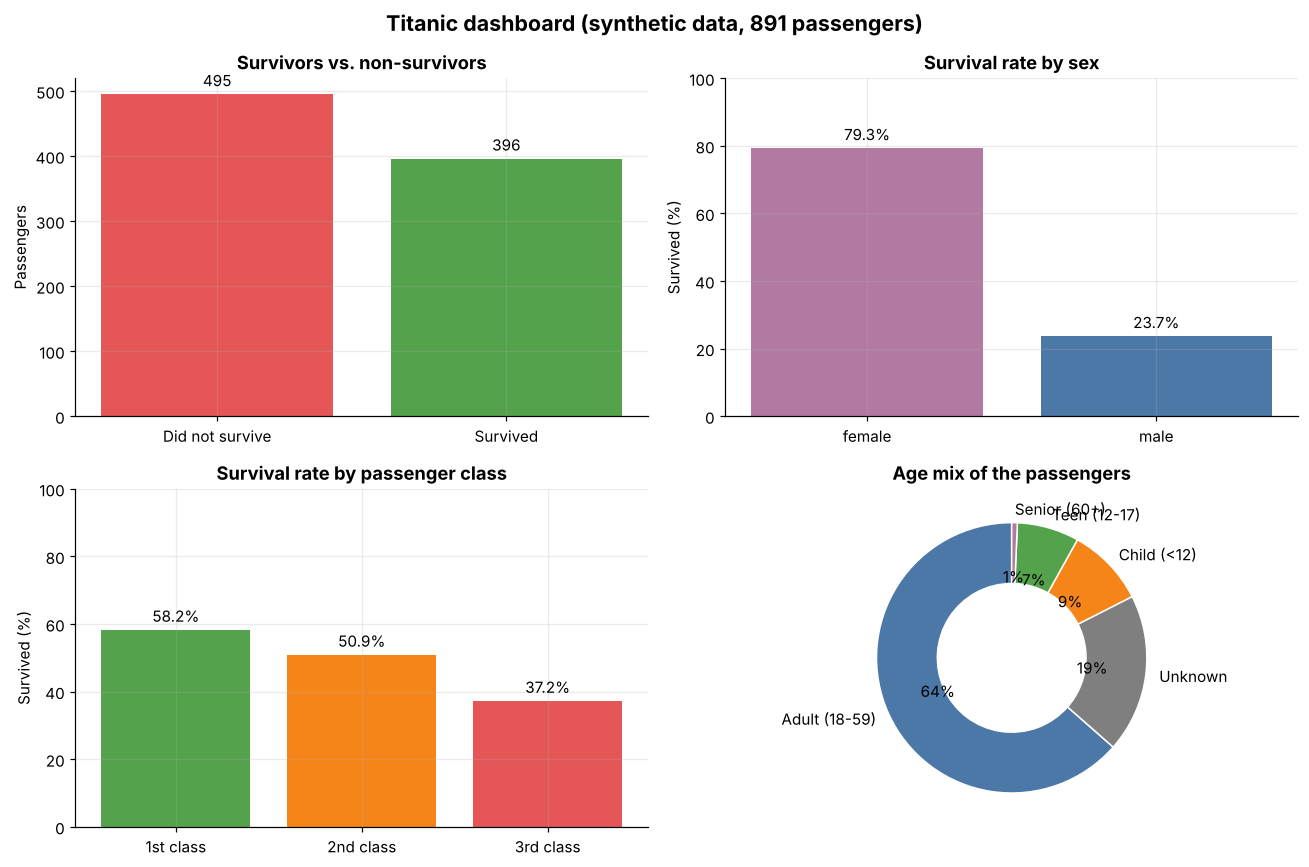

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# (a) survivors vs. non-survivors
counts = [total - survived, survived]
b = axes[0, 0].bar(["Did not survive", "Survived"], counts, color=[COLORS["red"], COLORS["green"]])
axes[0, 0].bar_label(b, padding=3)
axes[0, 0].set_title("Survivors vs. non-survivors")
axes[0, 0].set_ylabel("Passengers")

# (b) survival rate by sex
by_sex = df.groupby("Sex")["Survived"].mean() * 100
b = axes[0, 1].bar(by_sex.index, by_sex.values, color=[COLORS["purple"], COLORS["blue"]])
axes[0, 1].bar_label(b, fmt="%.1f%%", padding=3)
axes[0, 1].set_ylim(0, 100)
axes[0, 1].set_title("Survival rate by sex")
axes[0, 1].set_ylabel("Survived (%)")

# (c) survival rate by class
by_class = df.groupby("Class")["Survived"].mean() * 100
b = axes[1, 0].bar(by_class.index, by_class.values, color=[COLORS["green"], COLORS["orange"], COLORS["red"]])
axes[1, 0].bar_label(b, fmt="%.1f%%", padding=3)
axes[1, 0].set_ylim(0, 100)
axes[1, 0].set_title("Survival rate by passenger class")
axes[1, 0].set_ylabel("Survived (%)")

# (d) age mix (donut)
mix = df["Age group"].value_counts()
axes[1, 1].pie(mix.values, labels=mix.index, autopct="%1.0f%%", startangle=90,
               wedgeprops={"width": 0.45, "edgecolor": "white"},
               colors=[COLORS["blue"], COLORS["grey"], COLORS["orange"], COLORS["green"], COLORS["purple"]][:len(mix)])
axes[1, 1].set_title("Age mix of the passengers")
axes[1, 1].grid(False)

fig.suptitle(f"Titanic dashboard (synthetic data, {total} passengers)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### Age distribution — who is a minor?

The dashed line marks age 18. Everything to its left is counted in `minors`.

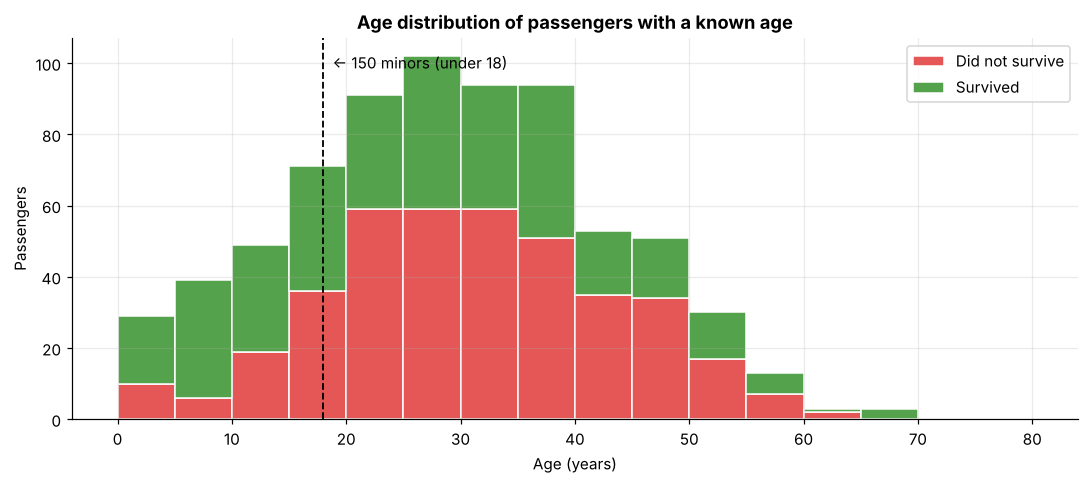

In [22]:
ages_died = df.loc[df.Survived == 0, "Age"].dropna()
ages_lived = df.loc[df.Survived == 1, "Age"].dropna()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist([ages_died, ages_lived], bins=range(0, 85, 5), stacked=True,
        color=[COLORS["red"], COLORS["green"]], label=["Did not survive", "Survived"], edgecolor="white")
ax.axvline(18, color="black", linestyle="--", linewidth=1.2)
ax.text(18.8, ax.get_ylim()[1] * 0.92, f"← {minors} minors (under 18)", fontsize=10)
ax.set_title("Age distribution of passengers with a known age")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Passengers")
ax.legend()
plt.tight_layout()
plt.show()

### Heat map — survival rate by sex and class

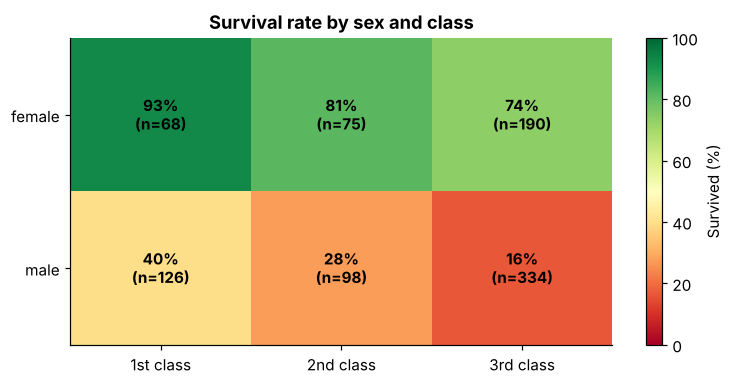

Class,1st class,2nd class,3rd class
Sex,,,
female,92.6,81.3,73.7
male,39.7,27.6,16.5


In [23]:
rate_pivot = df.pivot_table(index="Sex", columns="Class", values="Survived", aggfunc="mean") * 100
count_pivot = df.pivot_table(index="Sex", columns="Class", values="Survived", aggfunc="count")

fig, ax = plt.subplots(figsize=(7, 3.6))
im = ax.imshow(rate_pivot.values, cmap="RdYlGn", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(rate_pivot.shape[1]), rate_pivot.columns)
ax.set_yticks(range(rate_pivot.shape[0]), rate_pivot.index)
for i in range(rate_pivot.shape[0]):
    for j in range(rate_pivot.shape[1]):
        ax.text(j, i, f"{rate_pivot.values[i, j]:.0f}%\n(n={count_pivot.values[i, j]})",
                ha="center", va="center", fontsize=10, fontweight="bold")
ax.grid(False)
ax.set_title("Survival rate by sex and class")
fig.colorbar(im, ax=ax, label="Survived (%)")
plt.tight_layout()
plt.show()

rate_pivot.round(1)

### Grouped bars — women vs. men in each class

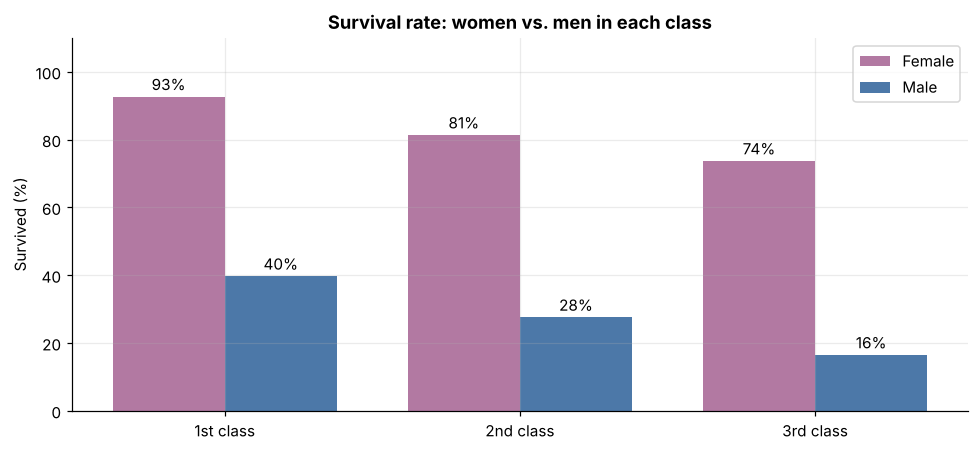

In [24]:
grouped = df.pivot_table(index="Class", columns="Sex", values="Survived", aggfunc="mean") * 100
x = np.arange(len(grouped))
w = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
b1 = ax.bar(x - w / 2, grouped["female"], w, label="Female", color=COLORS["purple"])
b2 = ax.bar(x + w / 2, grouped["male"], w, label="Male", color=COLORS["blue"])
ax.bar_label(b1, fmt="%.0f%%", padding=2)
ax.bar_label(b2, fmt="%.0f%%", padding=2)
ax.set_xticks(x, grouped.index)
ax.set_ylim(0, 110)
ax.set_ylabel("Survived (%)")
ax.set_title("Survival rate: women vs. men in each class")
ax.legend()
plt.tight_layout()
plt.show()

### Fares — box plot and scatter plot

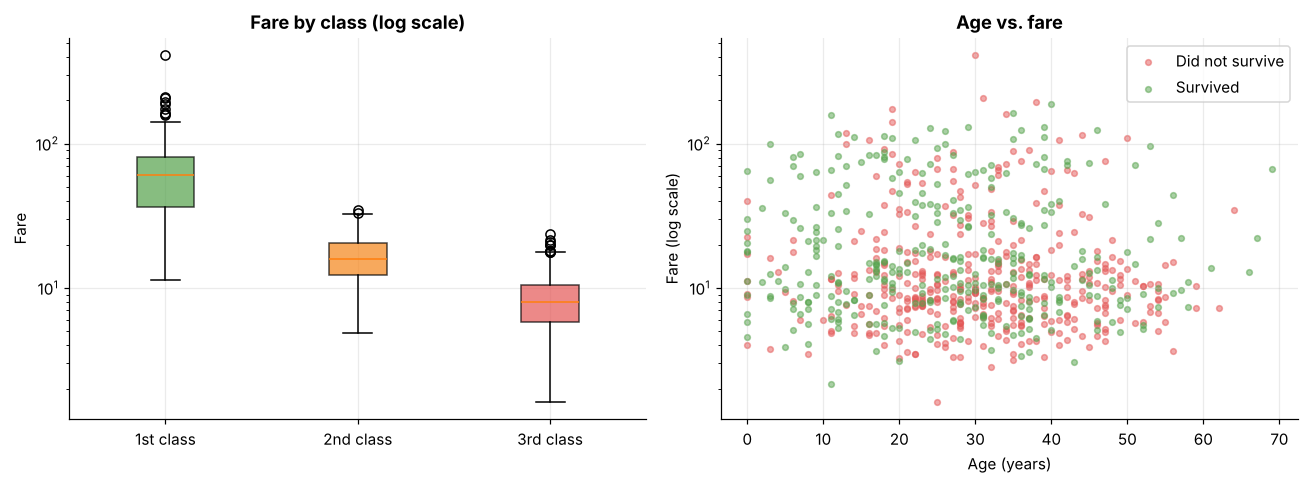

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: fare by class
data = [df.loc[df.Pclass == c, "Fare"] for c in (1, 2, 3)]
bp = axes[0].boxplot(data, patch_artist=True, showfliers=True)
for patch, c in zip(bp["boxes"], [COLORS["green"], COLORS["orange"], COLORS["red"]]):
    patch.set_facecolor(c)
    patch.set_alpha(0.7)
axes[0].set_xticks([1, 2, 3], ["1st class", "2nd class", "3rd class"])
axes[0].set_yscale("log")
axes[0].set_title("Fare by class (log scale)")
axes[0].set_ylabel("Fare")

# Right: age vs. fare, coloured by survival
known = df.dropna(subset=["Age"])
for flag, label, c in [(0, "Did not survive", COLORS["red"]), (1, "Survived", COLORS["green"])]:
    part = known[known.Survived == flag]
    axes[1].scatter(part["Age"], part["Fare"], s=14, alpha=0.5, color=c, label=label)
axes[1].set_yscale("log")
axes[1].set_title("Age vs. fare")
axes[1].set_xlabel("Age (years)")
axes[1].set_ylabel("Fare (log scale)")
axes[1].legend()

plt.tight_layout()
plt.show()

### Correlation heat map

A correlation of +1 means two columns rise together, −1 means one rises while the other falls, and 0 means no straight-line link.

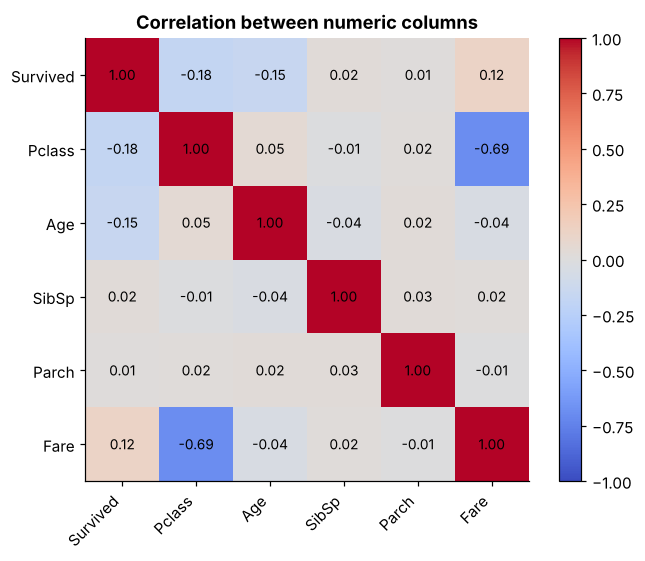

In [26]:
num_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
corr = titanic_data[num_cols].corr()

fig, ax = plt.subplots(figsize=(6.5, 5.2))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)), num_cols, rotation=45, ha="right")
ax.set_yticks(range(len(num_cols)), num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.grid(False)
ax.set_title("Correlation between numeric columns")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

# Professional features

Now we turn the loose calculations into reusable, tested code:

1. a **data class** that holds the results,
2. a **function with type hints** and input validation,
3. **tests** that also cover edge cases,
4. **export** to CSV and JSON,
5. a **reproducibility report**.

In [27]:
@dataclass(frozen=True)
class TitanicSummary:
    """Headline numbers of the passenger table."""
    total: int
    survived: int
    minors: int
    known_age: int

    @property
    def survived_fraction(self) -> float:
        return self.survived / self.total

    @property
    def minors_fraction(self) -> float:
        return self.minors / self.total

    @property
    def minors_fraction_of_known_age(self) -> float:
        return self.minors / self.known_age

    def to_dict(self) -> dict:
        return {**self.__dict__,
                "survived_fraction": round(self.survived_fraction, 6),
                "minors_fraction": round(self.minors_fraction, 6),
                "minors_fraction_of_known_age": round(self.minors_fraction_of_known_age, 6)}


def summarise(frame: pd.DataFrame) -> TitanicSummary:
    """Return the headline numbers; raise a clear error for bad input."""
    missing = {"Survived", "Age"} - set(frame.columns)
    if missing:
        raise KeyError(f"Missing column(s): {sorted(missing)}")
    if frame.empty:
        raise ValueError("The table has no rows.")
    ages = frame["Age"].dropna()
    return TitanicSummary(total=len(frame),
                          survived=int((frame["Survived"] == 1).sum()),
                          minors=int((ages < 18).sum()),
                          known_age=len(ages))

summary = summarise(titanic_data)
print(summary)
print(f"Survived fraction              : {summary.survived_fraction:.4f}")
print(f"Minors fraction (of everyone)  : {summary.minors_fraction:.4f}")
print(f"Minors fraction (known ages)   : {summary.minors_fraction_of_known_age:.4f}")

TitanicSummary(total=891, survived=396, minors=150, known_age=722)
Survived fraction              : 0.4444
Minors fraction (of everyone)  : 0.1684
Minors fraction (known ages)   : 0.2078


### Tests

In [28]:
# 1. The function agrees with the manual calculations above
check("summarise() matches the manual calculations",
      (summary.total, summary.survived, summary.minors) == (total, int(survived), int(minors)))

# 2. A tiny table where we know the answer: 2 of 4 survived, 2 of 4 are minors (ages 10 and 17)
tiny = pd.DataFrame({"Survived": [1, 0, 1, 0], "Age": [10, 30, np.nan, 17]})
s = summarise(tiny)
check("Tiny table: survived fraction is 0.5", s.survived_fraction == 0.5)
check("Tiny table: minors fraction is 0.5", s.minors_fraction == 0.5)
check("Tiny table: minors fraction of known ages is 2/3", abs(s.minors_fraction_of_known_age - 2 / 3) < 1e-12)

# 3. Bad input gives clear errors
for bad, error in [(pd.DataFrame({"Survived": []}), KeyError), (tiny.iloc[0:0], ValueError)]:
    try:
        summarise(bad)
        raised = False
    except error:
        raised = True
    check(f"Bad input raises {error.__name__}", raised)

✅ PASS - summarise() matches the manual calculations
✅ PASS - Tiny table: survived fraction is 0.5
✅ PASS - Tiny table: minors fraction is 0.5
✅ PASS - Tiny table: minors fraction of known ages is 2/3
✅ PASS - Bad input raises KeyError
✅ PASS - Bad input raises ValueError


### Export the results

In [29]:
out_dir = Path("outputs")
out_dir.mkdir(exist_ok=True)

(out_dir / "summary.json").write_text(json.dumps(summary.to_dict(), indent=2))
survival_summary.to_csv(out_dir / "survival_summary.csv", index=False)
scenarios.to_csv(out_dir / "birth_scenarios.csv", index=False)
compare.to_csv(out_dir / "year_comparison.csv", index=False)

pd.DataFrame({"File": [p.name for p in sorted(out_dir.iterdir())],
              "Size (bytes)": [p.stat().st_size for p in sorted(out_dir.iterdir())]})

,File,Size (bytes)
0,birth_scenarios.csv,348
1,summary.json,181
2,survival_summary.csv,595
3,year_comparison.csv,637


### Scoreboard — every check in this notebook

In [30]:
scoreboard = pd.DataFrame(RESULTS)
passed = (scoreboard["Result"] == "✅ Pass").sum()
print(f"{passed} of {len(scoreboard)} checks passed")

scoreboard.style.hide(axis="index")

14 of 14 checks passed


Check,Result,Detail
"Q1: the message 'Hello, world!' was printed",✅ Pass,
Q2: a custom message was printed,✅ Pass,
"Q3: comments are ignored, uncommented code runs",✅ Pass,
"Q4A: seconds in 5 years is 157,680,000",✅ Pass,
Q4B: births_per_day = births_per_min x 60 x 24,✅ Pass,"396,000"
Q5: survived_fraction is between 0 and 1,✅ Pass,0.4444
Q5: minors_fraction is between 0 and 1,✅ Pass,0.1684
Q5: survived_fraction = survived / total,✅ Pass,
summarise() matches the manual calculations,✅ Pass,
Tiny table: survived fraction is 0.5,✅ Pass,


### Reproducibility report

In [31]:
report = pd.DataFrame({
    "Item": ["Author", "Created", "Random seed", "Python", "NumPy", "pandas", "Rows in the table", "Checks passed"],
    "Value": [AUTHOR, datetime.now().strftime("%Y-%m-%d %H:%M"), SEED, platform.python_version(),
              np.__version__, pd.__version__, f"{total:,}", f"{passed} / {len(scoreboard)}"],
})
report.style.hide(axis="index")

Item,Value
Author,Harpreet Singh
Created,2026-11-04 16:48
Random seed,2026
Python,3.12.3
NumPy,2.5.4
pandas,3.0.6
Rows in the table,891
Checks passed,14 / 14


# Summary

| Question | What you learned | Key result in this edition |
| --- | --- | --- |
| 1 | `print()` shows a message | `Hello, world!` |
| 2 | Text needs quotes, arithmetic does not | `"3+4"` prints text, `3 + 4` prints 7 |
| 3 | `#` makes a comment | `print(1 + 2)` runs, the commented copy does not |
| 4 | Variables make calculations readable | 5 years = 157,680,000 s; 275 births/min = 396,000 per day |
| 5 | A fraction is `part / whole` | `survived / total` and `minors / total` |

## Keep going

Next: **[organize your code with functions](https://www.kaggle.com/alexisbcook/functions)**.

*Original exercise: [Intro to Programming](https://www.kaggle.com/learn/intro-to-programming) by Kaggle. This upgraded edition was prepared for **Harpreet Singh**.*